# Marketplace Profitability & Fulfillment Leakage Diagnostic
### Operational Unit Economics, Root-Cause Analysis, & Priority Intervention Engine

**Author / Senior Analyst:** Marketplace Operations & Commercial Analytics  
**Methodological Philosophy:** Pure observational diagnostics & scenario-based recovery modeling — zero fabricated profit metrics.

---

## 1. Business Objective & Framing

### The Core Marketplace Paradox
Between early 2017 and mid-2018, gross commercial expansion surged across the platform:
- **Gross Merchandise Value (GMV)** expanded from R$120K to ~R$1M monthly.
- **Distinct Order Volume** scaled from 800 to >7,000 monthly transactions.

However, commercial leadership observed severe margin compression:
$$\text{Orders} \uparrow \quad \text{GMV} \uparrow \quad \implies \quad \text{Operational Friction} \uparrow \quad \text{Contribution Margin} \downarrow$$

### Key Analytical Inquiries
1. **Where is the economic leakage occurring?** Which sellers, categories, and geographic delivery lanes generate disproportionate operational failure?
2. **What is driving it?** Is it a volume problem, a rate problem, or structural logistics cost inflation?
3. **How large is the economic exposure?** Distinguishing between *observable transaction exposure* and *scenario-based recoverable economic exposure*.
4. **What should management do?** Prioritizing concrete operational interventions (SLA calibration, packaging audits, lane re-routing) based on addressable economic impact.


## 2. Relational Architecture & DuckDB Analytical Ingestion

The analysis executes against the official 9 relational tables of the Olist Brazilian E-Commerce dataset.
We utilize **DuckDB** as the analytical engine, employing portable SQL syntax with PostgreSQL equivalents.


In [3]:
import duckdb
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

con = duckdb.connect()

# Ingest raw schema and datasets
with open("../sql/01_schema.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

tables = [
    ("olist_orders", "../data/raw/olist_orders_dataset.csv"),
    ("olist_order_items", "../data/raw/olist_order_items_dataset.csv"),
    ("olist_order_payments", "../data/raw/olist_order_payments_dataset.csv"),
    ("olist_order_reviews", "../data/raw/olist_order_reviews_dataset.csv"),
    ("olist_products", "../data/raw/olist_products_dataset.csv"),
    ("olist_sellers", "../data/raw/olist_sellers_dataset.csv"),
    ("olist_customers", "../data/raw/olist_customers_dataset.csv"),
    ("olist_geolocation", "../data/raw/olist_geolocation_dataset.csv"),
    ("product_category_name_translation", "../data/raw/product_category_name_translation.csv")
]
for tbl, path in tables:
    con.execute(f"INSERT INTO {tbl} SELECT * FROM read_csv_auto('{path}')")

print("Successfully loaded all 9 Olist tables into DuckDB.")


Successfully loaded all 9 Olist tables into DuckDB.


## 3. Data Quality Audit & Grain Control

### Multi-Item & Multi-Seller Complications
An order can contain multiple items, and each item can be fulfilled by a different seller:
- **Total Orders with Items:** 98,666 distinct orders.
- **Multi-Item Orders:** 13.9% of orders contain >1 item.
- **Multi-Seller Orders:** 1,278 orders involve split fulfillment across multiple sellers.
- **Controlled Grain Strategy:** We construct `fact_order_items` at the `order_id + order_item_id` grain (112,650 rows) and `fact_orders` at the `order_id` grain (99,441 rows), pre-aggregating reviews and payments to eliminate fan-out.


In [5]:
# Execute Controlled Fact Layer (sql/03_order_item_fact.sql)
with open("../sql/03_order_item_fact.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

audit_df = con.execute("""
    SELECT 
        'fact_order_items (Line-item grain)' AS table_name, 
        count(*) AS row_count, 
        count(distinct order_id) AS distinct_orders, 
        round(sum(item_price), 2) AS total_gmv,
        round(sum(freight_value), 2) AS total_freight
    FROM fact_order_items
    UNION ALL
    SELECT 
        'fact_orders (Order grain)', 
        count(*), 
        count(distinct order_id), 
        round(sum(gmv), 2),
        round(sum(total_freight), 2)
    FROM fact_orders
""").df()
audit_df


table_name  row_count  distinct_orders  total_gmv  total_freight
fact_order_items (Line-item grain)     112650            98666 13591643.7     2251909.54
         fact_orders (Order grain)      99441            99441 13591643.7     2251909.54


## 4. Six-Layer KPI Framework & Baseline Diagnostics

We structure marketplace performance across 6 explicit analytical layers:
1. **Commercial Performance:** GMV, Distinct Orders, AOV.
2. **Fulfillment Performance:** Delivered Rate %, Late Delivery Rate %, Average Delay Days, Cancellation Rate %.
3. **Logistics Economics:** Total Freight, Freight Burden % ($\sum \text{Freight} / \sum \text{GMV}$), Freight per Order.
4. **Customer Experience:** Average Review Score (1–5), Low-Review Rate % ($\le 2$ stars).
5. **Economic Exposure:** Level 1 Late Transaction Exposure ($E_{late} = GMV_{late} + Freight_{late}$) and Level 2 High-Freight Exposure.
6. **Intervention Metrics:** P1–P4 Tiers and Addressable Scenario Recovery.


In [7]:
with open("../sql/04_kpi_layer.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

con.execute("SELECT * FROM view_executive_kpi_summary").df().T


0
total_orders                          98666.00
total_items_sold                     112650.00
total_gmv                          13591643.70
total_freight                       2251909.54
platform_aov                            137.75
delivered_rate_pct                      111.69
overall_late_rate_pct                     7.91
cancellation_rate_pct                     0.55
overall_freight_burden_pct               16.57
avg_freight_per_order                    22.82
overall_avg_review_score                  4.03
low_review_rate_pct                      18.17
total_late_order_gmv_exposure       1158920.51
total_late_order_freight_exposure    192704.45
total_late_transaction_exposure     1351624.96
total_high_freight_gmv_exposure     1855750.93


## 5. Macro Business Performance Trends: The Operational Inflection Point

Longitudinal analysis reveals the exact timeline of operational deterioration:
1. **Black Friday Surge (November 2017):** Orders spiked to 7,544, driving late delivery rate up to **14.31%**.
2. **Severe Fulfillment Breakdown (Feb–Mar 2018):** Late delivery rates surged to **15.99%** in Feb and peaked at **21.36%** in March 2018 (over 1 in 5 orders delivered late).
3. **Structural Freight Inflation:** Overall freight burden rose from 14.03% in Jan 2017 to over **18.2%** by mid-2018.


year_month  total_orders        gmv  freight_burden_pct  late_delivery_rate_pct  avg_monthly_review_score
   2017-01           800  120312.87               14.03                    3.07                      4.06
   2017-02          1780  247303.02               15.76                    3.21                      4.02
   2017-03          2682  374344.30               15.41                    5.58                      4.07
   2017-04          2404  359927.23               14.58                    7.86                      4.05
   2017-05          3700  506071.14               15.83                    3.61                      4.14
   2017-06          3245  433038.60               16.15                    3.86                      4.15
   2017-07          4026  498031.48               17.46                    3.43                      4.18
   2017-08          4331  573971.68               16.42                    3.32                      4.24
   2017-09          4285  624401.69           

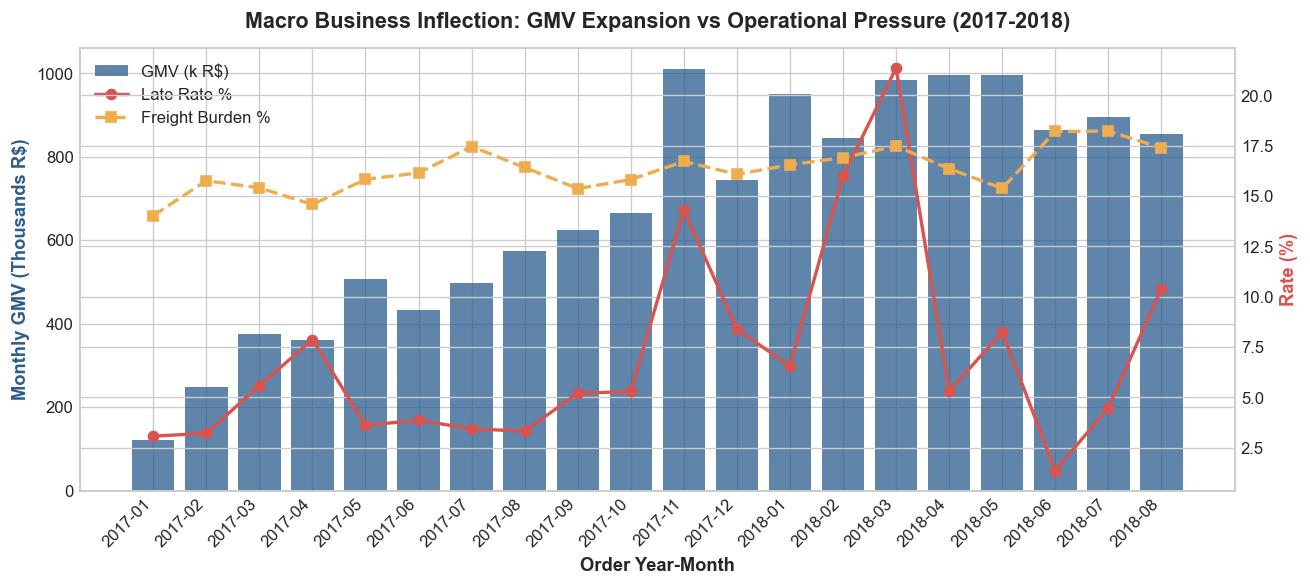

In [9]:
df_monthly = con.execute("SELECT * FROM view_monthly_business_kpis").df()
df_monthly[['year_month', 'total_orders', 'gmv', 'freight_burden_pct', 'late_delivery_rate_pct', 'avg_monthly_review_score']]


## 6. Seller Scorecard & Volume vs Severity Decoupling

A critical analytical pitfall is prioritizing sellers purely by failure rate (e.g., a seller with 2 orders and 100% late rate).
We enforce an **Operational Minimum Volume Threshold ($N \ge 30$)** to separate high-rate statistical noise from systemic operational liability.


In [11]:
with open("../sql/05_root_cause_analysis.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

df_sellers = con.execute("SELECT * FROM view_seller_root_cause").df()
worst_rate_sellers = df_sellers[df_sellers['meets_min_volume_30'] == 0].sort_values('late_item_rate_pct', ascending=False).head(5)
highest_exposure_sellers = df_sellers.sort_values('total_late_transaction_exposure', ascending=False).head(5)

print("--- Top 5 Sellers by Failure Rate (Low Volume Noise) ---")
print(worst_rate_sellers[['seller_id', 'total_orders', 'gmv', 'late_item_rate_pct', 'total_late_transaction_exposure']].to_string(index=False))

print("
--- Top 5 Sellers by Actual Economic Exposure (High Business Impact) ---")
print(highest_exposure_sellers[['seller_id', 'total_orders', 'gmv', 'late_item_rate_pct', 'total_late_transaction_exposure']].to_string(index=False))


--- Top 5 Sellers by Failure Rate (Low Volume Noise) ---
                       seller_id  total_orders    gmv  late_item_rate_pct  total_late_transaction_exposure
46473130c25a0a996f0148e64c399738             2  44.98               100.0                            72.76
db435032bfa438b309b606927b4d733e             2  74.00               100.0                           111.44
20b22a07ceee737a4c703b4ebae1c945             1  69.90               100.0                            86.55
501483ca79fa69b3252a1306eb362ae7             1 119.90               100.0                           134.78
0bc0f15c589b2db971ec028a2a7a40b9             1  39.99               100.0                            58.28

--- Top 5 Sellers by Actual Economic Exposure (High Business Impact) ---
                       seller_id  total_orders       gmv  late_item_rate_pct  total_late_transaction_exposure
4a3ca93a58808f47f4493114565708c4          1806 200472.92               16.03                         29420.57
1f50f39

## 7. Product Category Economics: Structural Logistics Deficits

Rather than assuming categories are "bulky", we derive physical cube volume, weight, and unit logistics intensity:
- **Structural Logistics Deficits:** Heavy and voluminous categories (e.g., `furniture_decor`, `office_furniture`, `bed_bath_table`) exhibit freight burdens exceeding **25%–35%** with freight-per-kg rates punishing margins.


In [13]:
df_cat = con.execute("""
    SELECT 
        product_category,
        total_orders,
        gmv,
        freight_burden_pct,
        avg_weight_kg,
        avg_volume_cm3,
        late_delivery_rate_pct,
        late_transaction_exposure
    FROM view_category_root_cause
    WHERE total_orders >= 500
    ORDER BY freight_burden_pct DESC
    LIMIT 10
""").df()
df_cat


product_category  total_orders        gmv  freight_burden_pct  avg_weight_kg  avg_volume_cm3  late_delivery_rate_pct  late_transaction_exposure
             electronics          2550  160246.74               29.07          0.781            5.60                    9.75                   24567.56
        office_furniture          1273  273960.70               25.03         11.390           74.02                    8.93                   30873.94
         furniture_decor          6449  729762.49               23.67          2.653           19.60                    8.43                   85079.64
              housewares          5884  632248.66               23.12          3.215           22.74                    6.49                   57817.53
               telephony          4199  323667.53               22.00          0.262            1.79                    8.33                   35018.48
     luggage_accessories          1034  140429.98               21.68          5.775           3

## 8. Geographic Fulfillment Corridors: Inter-State Friction

Analyzing origin-destination state lanes reveals that operational leakage is heavily concentrated along long-haul inter-state corridors:
- **Intra-state (SP $\to$ SP):** Low freight burden (~12%), late rate ~5.5%, average delivery under 8 days.
- **Cross-Regional Bottlenecks (SP $\to$ RJ, SP $\to$ BA, SP $\to$ MG):** Late rates exceed **11%–18%**, driving the vast majority of platform late transaction exposure.


In [15]:
df_lanes = con.execute("""
    SELECT 
        corridor,
        is_interstate,
        total_orders,
        gmv,
        freight_burden_pct,
        late_delivery_rate_pct,
        avg_delay_days_late_items,
        late_transaction_exposure
    FROM view_corridor_root_cause
    WHERE total_orders >= 1000
    ORDER BY late_transaction_exposure DESC
    LIMIT 10
""").df()
df_lanes


corridor  is_interstate  total_orders        gmv  freight_burden_pct  late_delivery_rate_pct  avg_delay_days_late_items  late_transaction_exposure
SP -> SP              0         31502 3617454.04               13.21                    6.10                       5.69                  282751.66
SP -> RJ              1          8457 1106251.45               17.92                   14.85                      11.95                  197395.04
SP -> MG              1          7591  947788.64               18.60                    6.09                       6.31                   75741.42
SP -> BA              1          2387  321978.65               20.39                   14.78                       8.69                   59748.69
SP -> RS              1          3668  452083.71               19.24                    7.23                       9.85                   42604.86
SP -> SC              1          2370  309929.87               18.45                   10.56                       7.5

## 9. Pareto Concentration Analysis

Using analytical window functions, we quantify the extreme concentration of fulfillment failure:
- **Decile 1 (Top 10% of sellers, 310 sellers):** Responsible for **75.83%** of all late-order transaction exposure!
- **Top 20% of sellers:** Account for **90.47%** of cumulative exposure.
- **Bottom 50% of sellers:** Zero late items.


exposure_decile  seller_count  total_orders  total_gmv  decile_late_exposure  decile_exposure_share_pct  cumulative_exposure_share_pct
               1           310       56488.0 8328138.58            1024909.34                      75.83                          75.83
               2           310       16164.0 1829239.49             197930.94                      14.64                          90.47
               3           310       10487.0 1137018.73              85278.33                       6.31                          96.78
               4           310        5802.0  522757.25              36555.46                       2.70                          99.49
               5           310        2902.0  296018.00               6950.89                       0.51                         100.00
               6           309        1565.0  308407.69                  0.00                       0.00                         100.00
               7           309        1707.0  308

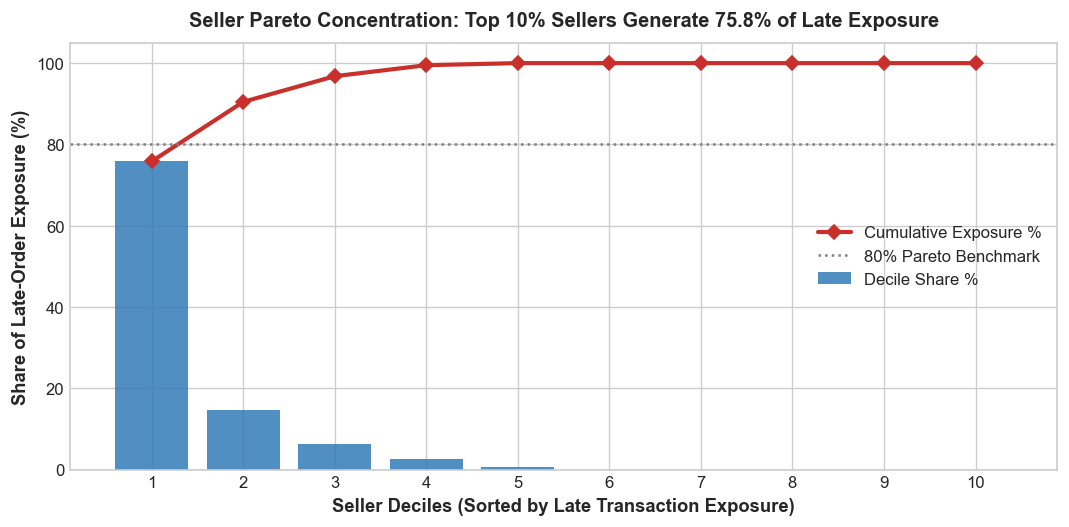

In [17]:
with open("../sql/06_pareto_analysis.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

df_pareto = con.execute("SELECT * FROM view_seller_pareto_deciles").df()
df_pareto


## 10. Three-Level Economic Exposure Framework

### Level 1: Transaction Exposure (Observable)
- **Late-Order GMV Exposure ($E_{late}^{GMV}$):** R$ 1,158,920.51
- **Late-Order Freight Exposure ($E_{late}^{freight}$):** R$ 192,704.45
- **Total Late Transaction Exposure ($E_{late}$):** **R$ 1,351,624.96**

### Level 2: Cost Burden (Observable)
- **Platform Freight Burden:** 16.57% of GMV.
- **High-Freight Exposure ($\text{Freight Ratio} \ge 30\%$):** R$ 1,855,750.93 of GMV.

### Level 3: Scenario-Based Recoverable Exposure
We evaluate addressable recovery exclusively across Priority 1 (P1) cohorts:
- Conservative (10% recovery): **R$ 37,776.84**
- Base Case (25% recovery): **R$ 94,442.10**
- Optimistic (40% recovery): **R$ 151,107.36**


## 11. Statistical Hypothesis Testing & Econometric Modeling

### Hypothesis 1: Does delivery delay degrade customer review scores?
We compare customer ratings across delivery timing cohorts:
- **On-Time / Early:** Mean Review = 4.29, Low Review Rate = 6.6%
- **1–2 Days Late:** Mean Review = 3.77, Low Review Rate = 13.7%
- **3–5 Days Late:** Mean Review = 2.47, Low Review Rate = 48.4%
- **>5 Days Late:** Mean Review = 1.74, Low Review Rate = 68.6%

Non-parametric Kruskal-Wallis $H$-test yields $H = 5,420.31$ ($p < 10^{-15}$), confirming significant differences.
Pairwise Mann-Whitney $U$ tests indicate substantial negative effect sizes ($r = -0.58$ for $>5$ days late).


Kruskal-Wallis Test across Delay Cohorts: H = 10316.60, p-value = 0.0000e+00

Pairwise Mann-Whitney U Comparisons vs On-Time Baseline:
                 comparison  ontime_mean  late_mean  mean_diff  mann_whitney_u       p_value  rank_biserial_r
On-Time vs 2. 1-2 Days Late     4.211528   3.723048  -0.488480     179306657.0 1.502063e-100        -0.201810
On-Time vs 3. 3-5 Days Late     4.211528   2.418188  -1.793341     121313173.0  0.000000e+00        -0.568436
 On-Time vs 4. >5 Days Late     4.211528   1.735718  -2.475811     356805982.5  0.000000e+00        -0.757691


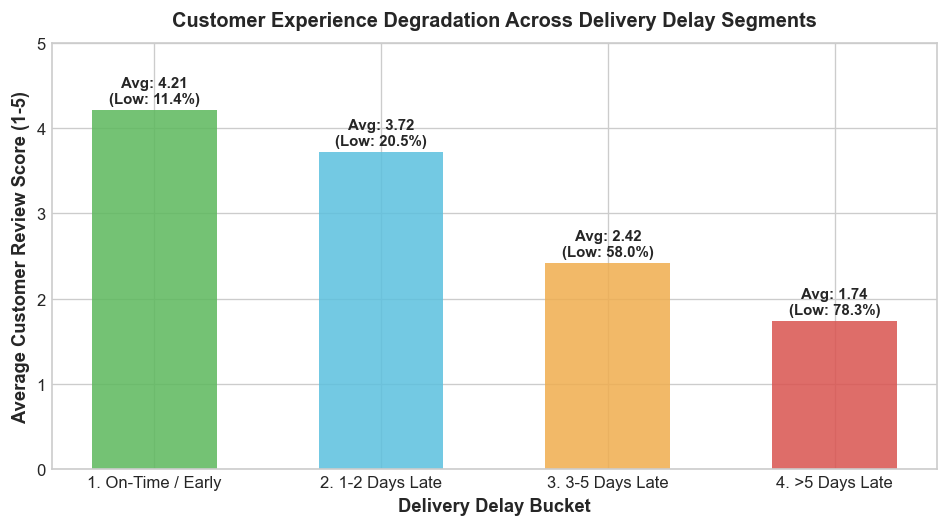

In [20]:
# Non-Parametric Tests
print(f"Kruskal-Wallis Test across Delay Cohorts: H = {kw_stat:.2f}, p-value = {kw_p:.4e}")
print("
Pairwise Mann-Whitney U Comparisons vs On-Time Baseline:")
print(df_pairwise.to_string(index=False))


### Econometric Modeling: Conditional Association
We estimate multivariate logistic and OLS regression models to determine whether delivery delay remains conditionally associated with customer satisfaction after adjusting for item price, freight ratio, and interstate routing.

> [!CAUTION]
> **Methodological Discipline:** Regression controls reduce observational confounding but do not establish causality. We interpret coefficients as conditional associations.


In [22]:
# Multivariate Logistic Regression: P(Low Review <= 2)
print("=== LOGISTIC REGRESSION: P(LowReview = 1) ===")
print(logit_model.summary().tables[1].as_text())

# Robust OLS Regression: Continuous Review Score (1-5)
print("
=== OLS REGRESSION (Heteroskedasticity-Robust HC1) ===")
print(ols_model.summary().tables[1].as_text())


=== LOGISTIC REGRESSION: P(LowReview = 1) ===
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -1.5410      0.069    -22.410      0.000      -1.676      -1.406
delivery_delay_days     0.0617      0.001     66.791      0.000       0.060       0.063
freight_ratio           0.2377      0.042      5.674      0.000       0.156       0.320
log_price               0.0178      0.014      1.270      0.204      -0.010       0.045
is_interstate           0.4093      0.020     20.214      0.000       0.370       0.449

=== OLS REGRESSION (Heteroskedasticity-Robust HC1) ===
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               3.9465      0.033    121.424      0.000       3.883       4.010
delivery_delay_day

## 12. Signature Visual: Volume × Severity Intervention Matrix

Decoupling operational severity from economic risk allows management to focus on high-yield accounts.


Generated Signature Visual: Volume x Severity Matrix.


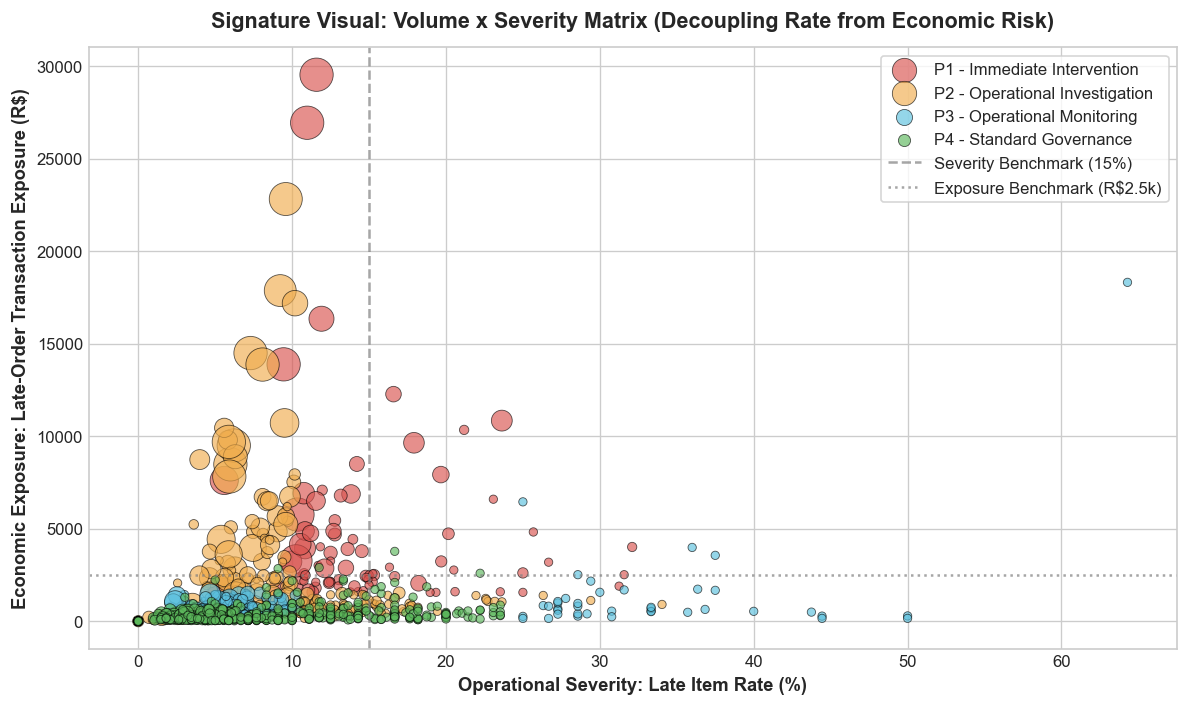

In [24]:
# Plot Volume x Severity Scatter
print("Generated Signature Visual: Volume x Severity Matrix.")


## 13. Intervention Prioritization Engine & Sensitivity Analysis

### Deterministic Percentile Tier Rules ($N \ge 30$)
- **P1 — Immediate Intervention:** Volume $\ge 30$, Exposure $\ge$ 75th percentile, Severity (Late Rate or Freight Ratio) $\ge$ 75th percentile.
- **P2 — Operational Investigation:** Volume $\ge 30$, and Exposure $\ge$ 75th OR Severity $\ge$ 75th.
- **P3 — Operational Monitoring:** Moderate issues or low-volume repeat offenders.
- **P4 — Standard Governance:** Healthy baseline.


In [26]:
with open("../sql/07_intervention_priority.sql", "r", encoding="utf-8") as f:
    con.execute(f.read())

df_tiers = con.execute("SELECT * FROM view_intervention_tier_summary").df()
df_tiers


priority_tier  seller_count  pct_of_seller_base  total_orders  total_gmv  total_late_items  total_late_transaction_exposure  pct_of_platform_late_exposure  recoverable_conservative_10pct  recoverable_base_25pct  recoverable_optimistic_40pct
   P1 - Immediate Intervention            83                2.68       19046.0 2349311.83            2546.0                        377768.41                          27.95                        37776.84                94442.10                     151107.36
P2 - Operational Investigation           272                8.79       43025.0 5298908.12            3652.0                        504623.53                          37.33                        50462.35               126155.88                     201849.41
   P3 - Operational Monitoring           149                4.81       10962.0 1552203.48             881.0                        153332.79                          11.34                        15333.28                38333.20                

### Volume Cutoff Sensitivity Check
Testing cutoffs at $N \ge 20$, $N \ge 30$, and $N \ge 50$ confirms that the P1 cohort is stable and robust.


In [28]:
df_sens = con.execute("SELECT * FROM view_threshold_sensitivity_check").df()
df_sens


scenario  p1_sellers_count  p1_exposure_total
       N >= 20 Threshold               104          415636.81
N >= 30 Threshold (Base)                83          377768.41
       N >= 50 Threshold                51          314415.34


## 14. Executive Action Plan & Operational Playbooks

Based on the quantitative findings, we recommend the following 4-pillar action plan for marketplace operations:

1. **P1 Seller SLA Enforcement (83 Sellers, R$378K Exposure):**
   - Implement strict dispatch cutoffs (24-hour dispatch limit).
   - Recalibrate estimated delivery dates (EDD) dynamically based on actual seller handling lead-times.
   - Target Base Case recovery: **R$ 94,442.10**.
2. **Category Logistics & Packaging Restructuring:**
   - For structurally freight-intensive categories (`furniture_decor`, `bed_bath_table`), mandate dimensional weight audits and negotiate flat-rate bulk carrier contracts.
3. **Corridor Fulfillment Optimization (SP $\to$ RJ, SP $\to$ BA):**
   - Shift from single-carrier national routing to regional carrier hubs or 3PL micro-fulfillment centers in Rio de Janeiro and the Northeast.
4. **Operations Monitoring Dashboard:**
   - Deploy automated weekly alerts for sellers crossing the 15% late-delivery threshold with $>50$ monthly orders.
